In [5]:

import pyodbc
import getpass

username = input("Enter SQL Server login username: ")
password = getpass.getpass("Enter SQL Server password: ")

conn = None

try:
    conn = pyodbc.connect(
        "DRIVER={ODBC Driver 18 for SQL Server};"
        "SERVER=localhost;"
        "DATABASE=AdventureWorks2022;"
        f"UID={username};"
        f"PWD={password};"
        "Encrypt=yes;"
        "TrustServerCertificate=yes;"
        "Connection Timeout=10;"f
    )

    print("Connected successfully!")

    cursor = conn.cursor()
    cursor.execute("SELECT @@SERVERNAME, DB_NAME()")

    print("Server and database:", cursor.fetchone())

    cursor.close()

except pyodbc.Error as e:
    print("Connection failed:", e)

finally:
    if conn:
        conn.close()


Connection failed: ('28000', "[28000] [Microsoft][ODBC Driver 18 for SQL Server][SQL Server]Login failed for user 'fff'. (18456) (SQLDriverConnect); [28000] [Microsoft][ODBC Driver 18 for SQL Server]Invalid connection string attribute (0); [28000] [Microsoft][ODBC Driver 18 for SQL Server][SQL Server]Login failed for user 'fff'. (18456); [28000] [Microsoft][ODBC Driver 18 for SQL Server]Invalid connection string attribute (0)")


In [7]:

import pyodbc

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 18 for SQL Server};"
    "SERVER=localhost;"
    "DATABASE=AdventureWorks2022;"
    "Trusted_Connection=yes;"
    "Encrypt=yes;"
    "TrustServerCertificate=yes;"
)

print("Connected successfully!")

cursor = conn.cursor()
cursor.execute("SELECT TOP 5 ProductID, Name, ListPrice FROM Production.Product")

for row in cursor.fetchall():
    print(row)

cursor.close()
conn.close()


Connected successfully!
(1, 'Adjustable Race', Decimal('0.0000'))
(2, 'Bearing Ball', Decimal('0.0000'))
(3, 'BB Ball Bearing', Decimal('0.0000'))
(4, 'Headset Ball Bearings', Decimal('0.0000'))
(316, 'Blade', Decimal('0.0000'))


In [8]:
import pandas as pd

query = """
SELECT TOP 10 ProductID, Name, ListPrice
FROM Production.Product
ORDER BY ListPrice DESC
"""

df = pd.read_sql_query(query, conn)
print(df)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21980\3052320551.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


ProgrammingError: Attempt to use a closed connection.

In [9]:

import pyodbc
import pandas as pd

conn = None

try:
    # Connect to SQL Server using Windows Authentication
    conn = pyodbc.connect(
        "DRIVER={ODBC Driver 18 for SQL Server};"
        "SERVER=localhost;"
        "DATABASE=AdventureWorks2022;"
        "Trusted_Connection=yes;"
        "Encrypt=yes;"
        "TrustServerCertificate=yes;"
    )

    query = """
    SELECT TOP 10 ProductID, Name, ListPrice
    FROM Production.Product
    ORDER BY ListPrice DESC
    """

    df = pd.read_sql_query(query, conn)

    print(df)

except pyodbc.Error as e:
    print("Database error:", e)

finally:
    if conn is not None:
        conn.close()
        print("Connection closed.")


   ProductID                     Name  ListPrice
0        749         Road-150 Red, 62    3578.27
1        750         Road-150 Red, 44    3578.27
2        751         Road-150 Red, 48    3578.27
3        752         Road-150 Red, 52    3578.27
4        753         Road-150 Red, 56    3578.27
5        771  Mountain-100 Silver, 38    3399.99
6        772  Mountain-100 Silver, 42    3399.99
7        773  Mountain-100 Silver, 44    3399.99
8        774  Mountain-100 Silver, 48    3399.99
9        775   Mountain-100 Black, 38    3374.99
Connection closed.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21980\1165037206.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


In [10]:
import pyodbc
import pandas as pd

conn = None

try:
    # Connect to SQL Server using Windows Authentication
    conn = pyodbc.connect(
        "DRIVER={ODBC Driver 18 for SQL Server};"
        "SERVER=localhost;"
        "DATABASE=AdventureWorks2022;"
        "Trusted_Connection=yes;"
        "Encrypt=yes;"
        "TrustServerCertificate=yes;"
    )

    query = """
    SELECT TOP 10 ProductID, Name, ListPrice
    FROM Production.Product
    ORDER BY ListPrice DESC
    """

    df = pd.read_sql_query(query, conn)

    print(df)

except pyodbc.Error as e:
    print("Database error:", e)


   ProductID                     Name  ListPrice
0        749         Road-150 Red, 62    3578.27
1        750         Road-150 Red, 44    3578.27
2        751         Road-150 Red, 48    3578.27
3        752         Road-150 Red, 52    3578.27
4        753         Road-150 Red, 56    3578.27
5        771  Mountain-100 Silver, 38    3399.99
6        772  Mountain-100 Silver, 42    3399.99
7        773  Mountain-100 Silver, 44    3399.99
8        774  Mountain-100 Silver, 48    3399.99
9        775   Mountain-100 Black, 38    3374.99


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21980\2895644450.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


In [14]:
query=""" Select ProductID, Name, ListPrice
    FROM Production.Product
    ORDER BY ListPrice DESC """

df=pd.read_sql_query(query,conn)

print(df.head())

   ProductID              Name  ListPrice
0        749  Road-150 Red, 62    3578.27
1        750  Road-150 Red, 44    3578.27
2        751  Road-150 Red, 48    3578.27
3        752  Road-150 Red, 52    3578.27
4        753  Road-150 Red, 56    3578.27


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21980\452408738.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql_query(query,conn)


In [19]:
query = """
select top 10 ProductID, Name, ListPrice from Production.Product where listprice<>0 order by listprice DESC
"""

df = pd.read_sql_query(query, conn)
print(df)

   ProductID                     Name  ListPrice
0        749         Road-150 Red, 62    3578.27
1        750         Road-150 Red, 44    3578.27
2        751         Road-150 Red, 48    3578.27
3        752         Road-150 Red, 52    3578.27
4        753         Road-150 Red, 56    3578.27
5        771  Mountain-100 Silver, 38    3399.99
6        772  Mountain-100 Silver, 42    3399.99
7        773  Mountain-100 Silver, 44    3399.99
8        774  Mountain-100 Silver, 48    3399.99
9        775   Mountain-100 Black, 38    3374.99


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21980\3818542599.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

query = """
SELECT TOP 10 Name, ListPrice
FROM Production.Product
WHERE ListPrice > 0
ORDER BY ListPrice DESC
"""

df = pd.read_sql_query(query, conn)

print(df)

                      Name  ListPrice
0         Road-150 Red, 62    3578.27
1         Road-150 Red, 44    3578.27
2         Road-150 Red, 48    3578.27
3         Road-150 Red, 52    3578.27
4         Road-150 Red, 56    3578.27
5  Mountain-100 Silver, 38    3399.99
6  Mountain-100 Silver, 42    3399.99
7  Mountain-100 Silver, 44    3399.99
8  Mountain-100 Silver, 48    3399.99
9   Mountain-100 Black, 38    3374.99


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21980\3558774670.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


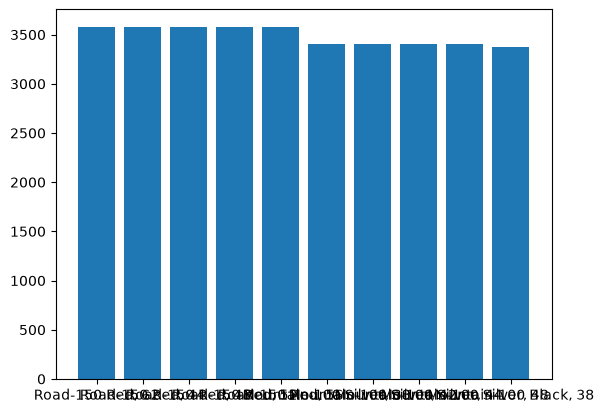

In [25]:
plt.bar(df["Name"], df["ListPrice"])
plt.show()